# Training Curves — Novel Indian CSI Ablation

One subplot per ablation row.  
Each subplot shows **val MAP vs epoch** with two traces:
- **solid** line → trained on `indian` (mix)
- **dashed** line → trained on `indian_vocal` (vocal stems)

A star marker (★) indicates the best epoch for each run.  
Rows where `indian_vocal` training hasn't run yet show only one trace.

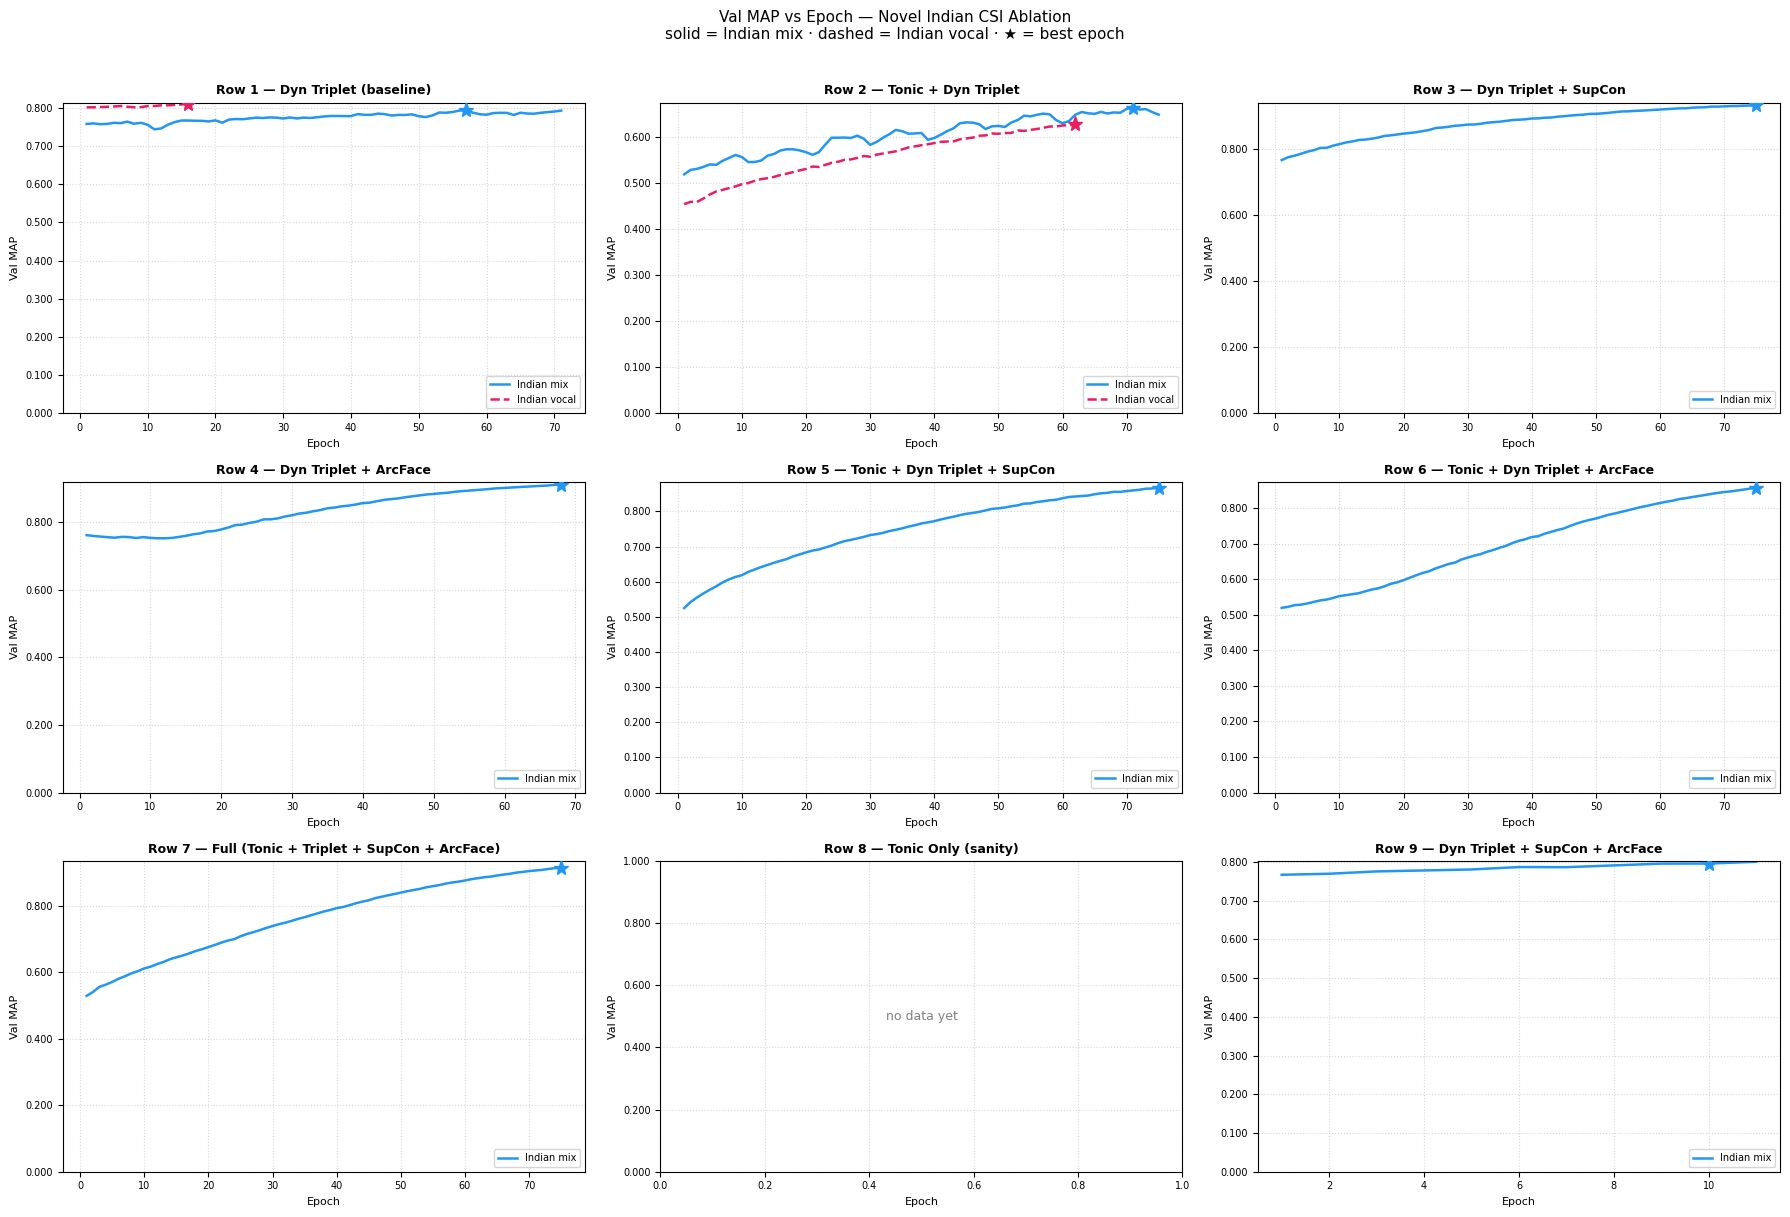

Saved → results/figures/training_curves.png


In [1]:
import json
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

LOG_DIR = Path("logs")

# ── Collect latest log per (row_name, dataset) ──────────────────────────────
latest = {}   # (row_name, dataset) -> dict
for path in sorted(LOG_DIR.glob("row*.json")):
    with open(path) as f:
        d = json.load(f)
    key = (d["row_name"], d["dataset"])
    if key not in latest or path.stat().st_mtime > Path(latest[key]["_path"]).stat().st_mtime:
        d["_path"] = str(path)
        latest[key] = d

# ── Row ordering + display labels ───────────────────────────────────────────
ROW_ORDER = [
    ("row1_baseline_dyn_triplet",          "Row 1 — Dyn Triplet (baseline)"),
    ("row2_tonic_dyn_triplet",             "Row 2 — Tonic + Dyn Triplet"),
    ("row3_dyn_triplet_supcon",            "Row 3 — Dyn Triplet + SupCon"),
    ("row4_dyn_triplet_arcface",           "Row 4 — Dyn Triplet + ArcFace"),
    ("row5_tonic_dyn_triplet_supcon",      "Row 5 — Tonic + Dyn Triplet + SupCon"),
    ("row6_tonic_dyn_triplet_arcface",     "Row 6 — Tonic + Dyn Triplet + ArcFace"),
    ("row7_full",                          "Row 7 — Full (Tonic + Triplet + SupCon + ArcFace)"),
    ("row8_tonic_only",                    "Row 8 — Tonic Only (sanity)"),
    ("row9_dyn_triplet_supcon_arcface",    "Row 9 — Dyn Triplet + SupCon + ArcFace"),
]

# ── Figure layout ────────────────────────────────────────────────────────────
N = len(ROW_ORDER)
NCOLS = 3
NROWS = int(np.ceil(N / NCOLS))

COLORS = {
    "indian":       ("#2196F3", "-",  "Indian mix"),
    "indian_vocal": ("#E91E63", "--", "Indian vocal"),
}

fig, axes = plt.subplots(
    NROWS, NCOLS,
    figsize=(6 * NCOLS, 4 * NROWS),
    sharex=False, sharey=False,
)
axes = axes.flatten()

for idx, (row_name, label) in enumerate(ROW_ORDER):
    ax = axes[idx]

    any_plotted = False
    for ds, (color, ls, ds_label) in COLORS.items():
        key = (row_name, ds)
        if key not in latest:
            continue
        d = latest[key]
        hist = d.get("history", [])
        if not hist:
            continue

        epochs  = [h["epoch"]   for h in hist]
        val_map = [h["val_map"] for h in hist]
        best_ep = d.get("best_epoch")
        best_map = d.get("best_val_map")

        ax.plot(epochs, val_map, color=color, linestyle=ls,
                linewidth=1.8, label=ds_label, zorder=2)

        # Mark best epoch
        if best_ep is not None and best_map is not None:
            ax.plot(best_ep, best_map, marker="*", markersize=11,
                    color=color, zorder=3)
        any_plotted = True

    ax.set_title(label, fontsize=9, fontweight="bold", pad=6)
    ax.set_xlabel("Epoch", fontsize=8)
    ax.set_ylabel("Val MAP", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.set_ylim(bottom=0)

    if any_plotted:
        ax.legend(fontsize=7, loc="lower right")
    else:
        ax.text(0.5, 0.5, "no data yet", transform=ax.transAxes,
                ha="center", va="center", color="grey", fontsize=9)

# Hide any unused subplots
for j in range(N, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Val MAP vs Epoch — Novel Indian CSI Ablation\n"
    "solid = Indian mix · dashed = Indian vocal · ★ = best epoch",
    fontsize=11, y=1.01,
)
fig.tight_layout()
plt.savefig("results/figures/training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → results/figures/training_curves.png")

## Best val MAP summary table

In [2]:
import pandas as pd

rows = []
for row_name, label in ROW_ORDER:
    row = {"Row": label}
    for ds in ("indian", "indian_vocal"):
        key = (row_name, ds)
        if key in latest:
            d = latest[key]
            bm   = d.get("best_val_map")
            be   = d.get("best_epoch")
            n_ep = len(d.get("history", []))
            row[f"{ds} best MAP"]   = f"{bm:.4f}" if bm else "—"
            row[f"{ds} best epoch"] = f"{be}/{n_ep}" if be else "—"
        else:
            row[f"{ds} best MAP"]   = "not run"
            row[f"{ds} best epoch"] = "not run"
    rows.append(row)

df = pd.DataFrame(rows).set_index("Row")
pd.set_option("display.max_colwidth", 60)
df

,indian best MAP,indian best epoch,indian_vocal best MAP,indian_vocal best epoch
Row,,,,
Row 1 — Dyn Triplet (baseline),0.7935,57/71,0.8104,16/16
Row 2 — Tonic + Dyn Triplet,0.6630,71/75,0.6265,62/63
Row 3 — Dyn Triplet + SupCon,0.9310,75/75,not run,not run
Row 4 — Dyn Triplet + ArcFace,0.9120,68/68,not run,not run
Row 5 — Tonic + Dyn Triplet + SupCon,0.8670,75/75,not run,not run
Row 6 — Tonic + Dyn Triplet + ArcFace,0.8570,75/75,not run,not run
Row 7 — Full (Tonic + Triplet + SupCon + ArcFace),0.9154,75/75,not run,not run
Row 8 — Tonic Only (sanity),—,—,not run,not run
Row 9 — Dyn Triplet + SupCon + ArcFace,0.7955,10/11,not run,not run
